<a href="https://colab.research.google.com/github/anushagpatel/Fine_Tuning_Gretel_Text_to_SQL/blob/main/Gretel_Text_to_SQL_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gretel Text-to-SQL: baseline → LoRA fine-tuning → evaluation → Gradio
**Run top to bottom in Google Colab.** Choose **Runtime → Change runtime type → T4 GPU** (or better). This notebook uses a small, reproducible subset for a classroom experiment; expand after the first successful run. Training may take substantial time depending on GPU and Colab availability. **Do not run generated SQL against production databases.**

## 1. Install dependencies

In [3]:
%pip -q install -U "transformers>=4.46,<5" "datasets>=3,<5" "trl>=0.17,<1" "peft>=0.14,<1" "accelerate>=1,<2" "gradio>=5,<7" "sqlglot>=26" pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 496.6 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 531.0/531.0 kB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 777.8/777.8 kB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 68.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Check GPU and configure experiment

In [4]:
import os, gc, json, re, random, time
import numpy as np, pandas as pd, torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from pathlib import Path
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_ID="Qwen/Qwen2.5-Coder-1.5B-Instruct"
TRAIN_N=2000  # raise to 5000+ after smoke test
EVAL_N=60     # raise to 200 for stronger estimates
MAX_LENGTH=768
MAX_NEW_TOKENS=220
OUT=Path('/content/text2sql_results'); OUT.mkdir(exist_ok=True)
assert torch.cuda.is_available(), 'GPU required: Runtime > Change runtime type > T4 GPU'
print('GPU:',torch.cuda.get_device_name(0),'torch:',torch.__version__)

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition torch: 2.11.0+cu130


## 3. Load the official dataset splits; never train on test

In [5]:
ds=load_dataset('gretelai/synthetic_text_to_sql')
print(ds)
print('Columns:',ds['train'].column_names)
train_raw=ds['train'].shuffle(seed=SEED).select(range(min(TRAIN_N,len(ds['train']))))
test_raw=ds['test'].shuffle(seed=SEED).select(range(min(EVAL_N,len(ds['test']))))
print('Example:', {k:train_raw[0][k] for k in ['sql_context','sql_prompt','sql','sql_explanation']})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

synthetic_text_to_sql_train.snappy.parqu(…):   0%|          | 0.00/32.4M [00:00<?, ?B/s]

synthetic_text_to_sql_test.snappy.parque(…):   0%|          | 0.00/1.90M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5851 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation'],
        num_rows: 100000
    })
    test: Dataset({
        features: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation'],
        num_rows: 5851
    })
})
Columns: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation']
Example: {'sql_context': "CREATE TABLE Members (MemberID INT, Age INT, Gender VARCHAR(10), MembershipType VARCHAR(20)); INSERT INTO Members (MemberID, Age, Gender, MembershipType) VALUES (1, 35, 'Female', 'Premium'), (2, 45, 'Male', 'Basic'), (3, 28, 'Female', 'Premium

## 4. Format prompt and completion consistently for baseline, training and inference

In [6]:
SYSTEM='You generate SQL from a database schema and a question. Return exactly two sections: SQL: followed by a SQL statement, and Explanation: followed by a concise natural-language explanation. Do not invent schema columns.'
def user_text(row):
    return f"Database context:\n{row['sql_context']}\n\nQuestion: {row['sql_prompt']}"
def target_text(row):
    return f"SQL:\n{row['sql']}\nExplanation:\n{row['sql_explanation']}"
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None: tokenizer.pad_token=tokenizer.eos_token
def prompt_text(row):
    return tokenizer.apply_chat_template([{'role':'system','content':SYSTEM},{'role':'user','content':user_text(row)}],tokenize=False,add_generation_prompt=True)
def to_training(row):
    return {'prompt':prompt_text(row),'completion':target_text(row)+tokenizer.eos_token}
train_ds=train_raw.map(to_training,remove_columns=train_raw.column_names)
print(train_ds[0]['prompt'][:700]);print(train_ds[0]['completion'][:500])

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

<|im_start|>system
You generate SQL from a database schema and a question. Return exactly two sections: SQL: followed by a SQL statement, and Explanation: followed by a concise natural-language explanation. Do not invent schema columns.<|im_end|>
<|im_start|>user
Database context:
CREATE TABLE Members (MemberID INT, Age INT, Gender VARCHAR(10), MembershipType VARCHAR(20)); INSERT INTO Members (MemberID, Age, Gender, MembershipType) VALUES (1, 35, 'Female', 'Premium'), (2, 45, 'Male', 'Basic'), (3, 28, 'Female', 'Premium'), (4, 32, 'Male', 'Premium'), (5, 48, 'Female', 'Basic'); CREATE TABLE ClassAttendance (MemberID INT, Class VARCHAR(20), Date DATE); INSERT INTO ClassAttendance (MemberID, C
SQL:
SELECT Class, COUNT(*) as AttendanceCount FROM Members JOIN ClassAttendance ON Members.MemberID = ClassAttendance.MemberID WHERE MONTH(ClassAttendance.Date) = 4 GROUP BY Class;
Explanation:
We are joining the Members table with the ClassAttendance table based on the MemberID. We then filter th

## 5. Baseline generation on the pretrained model (before training)

In [7]:
dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
base=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype=dtype,device_map='auto')
base.eval()
def generate(model,rows):
    outputs=[]
    for i,row in enumerate(rows):
        inputs=tokenizer(prompt_text(row),return_tensors='pt',truncation=True,max_length=MAX_LENGTH).to('cuda')
        with torch.inference_mode():
            ids=model.generate(**inputs,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,pad_token_id=tokenizer.pad_token_id)
        outputs.append(tokenizer.decode(ids[0,inputs['input_ids'].shape[1]:],skip_special_tokens=True).strip())
        if (i+1)%10==0: print('Generated',i+1,'/',len(rows))
    return outputs
rows=list(test_raw)
baseline=generate(base,rows)
(OUT/'baseline_predictions.json').write_text(json.dumps(baseline,indent=2))
print('Baseline example:',baseline[0])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Generated 10 / 60
Generated 20 / 60
Generated 30 / 60
Generated 40 / 60
Generated 50 / 60
Generated 60 / 60
Baseline example: SQL:
```sql
SELECT name, maintenance_cost FROM MilitaryEquipment WHERE region = 'Atlantic' AND maintenance_cost < 5000;
```

Explanation:
This SQL query selects the `name` and `maintenance_cost` columns from the `MilitaryEquipment` table where the `region` is 'Atlantic' and the `maintenance_cost` is less than $5000. The result will be a list of all military equipment that meet these criteria, including their names and the amount they need to maintain.


## 6. Evaluate with normalized SQL exact match and SQLGlot parse success
Parse success is **not** semantic correctness. Execution accuracy is not measured because the dataset does not supply runnable databases for every example.

In [8]:
import sqlglot
from sqlglot import exp
def extract_sql(text):
    match=re.search(r'(?is)\bSQL\s*:\s*(.*?)(?=\bExplanation\s*:|$)',text)
    s=(match.group(1) if match else text).strip()
    s=re.sub(r'^```(?:sql)?\s*|\s*```$','',s,flags=re.I).strip()
    return s
def normalized(sql):
    try: return sqlglot.parse_one(sql).sql(pretty=False,normalize=True)
    except Exception: return re.sub(r'\s+',' ',sql.strip()).lower()
def metrics(preds,records):
    exact=[]; parsed=[]; explained=[]
    for p,r in zip(preds,records):
        sql=extract_sql(p)
        exact.append(normalized(sql)==normalized(r['sql']))
        try: parsed.append(bool(sqlglot.parse_one(sql)))
        except Exception: parsed.append(False)
        explained.append(bool(re.search(r'(?is)\bExplanation\s*:\s*\S+',p)))
    return {'sql_normalized_exact_match':round(np.mean(exact)*100,2),'sql_parse_success':round(np.mean(parsed)*100,2),'explanation_present':round(np.mean(explained)*100,2),'n':len(preds)}
before=metrics(baseline,rows)
print('Baseline:',before)

Baseline: {'sql_normalized_exact_match': np.float64(10.0), 'sql_parse_success': np.float64(100.0), 'explanation_present': np.float64(100.0), 'n': 60}


## 7. Free baseline model memory before training

In [11]:
del base; gc.collect(); torch.cuda.empty_cache()



NameError: name 'base' is not defined

In [12]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 8. LoRA supervised fine-tuning
Completion-only loss teaches the desired SQL and explanation rather than penalizing the model for prompt tokens. Reduce TRAIN_N or MAX_LENGTH if Colab runs out of memory.

In [13]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype=dtype,device_map='auto')
model.config.use_cache=False
lora=LoraConfig(r=16,lora_alpha=32,lora_dropout=0.05,bias='none',task_type='CAUSAL_LM',target_modules=['q_proj','k_proj','v_proj','o_proj'])
args=SFTConfig(output_dir=str(OUT/'checkpoints'),num_train_epochs=1,per_device_train_batch_size=1,gradient_accumulation_steps=8,learning_rate=2e-4,logging_steps=20,save_strategy='epoch',report_to='none',max_length=MAX_LENGTH,completion_only_loss=True,gradient_checkpointing=True,fp16=(dtype==torch.float16),bf16=(dtype==torch.bfloat16),seed=SEED)
trainer=SFTTrainer(model=model,args=args,train_dataset=train_ds,peft_config=lora,processing_class=tokenizer)
trainer.model.print_trainable_parameters()
result=trainer.train()
trainer.save_model(str(OUT/'lora_adapter'))
tokenizer.save_pretrained(str(OUT/'lora_adapter'))
print('Training:',result.metrics)

Adding EOS to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


Step,Training Loss
20,0.496900
40,0.450500
60,0.431600
80,0.436400
100,0.426100
120,0.416700
140,0.406200
160,0.425200
180,0.423100
200,0.403300


Training: {'train_runtime': 202.2699, 'train_samples_per_second': 9.888, 'train_steps_per_second': 1.236, 'total_flos': 3946005198587904.0, 'train_loss': 0.4251149826049805}


## 9. Compare after fine-tuning using the same held-out examples

Generated 10 / 60
Generated 20 / 60
Generated 30 / 60
Generated 40 / 60
Generated 50 / 60
Generated 60 / 60


,model,sql_normalized_exact_match,sql_parse_success,explanation_present,n
0,Before LoRA,10.00,100.0,100.0,60
1,After LoRA,28.33,100.0,100.0,60


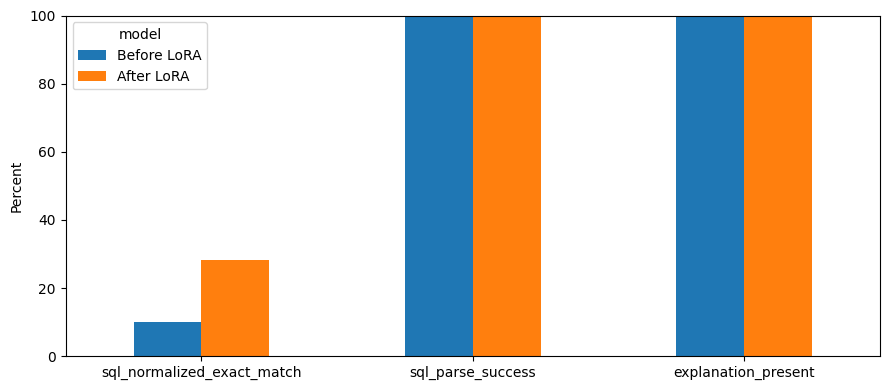

In [14]:
trainer.model.config.use_cache=True
trainer.model.eval()
after_preds=generate(trainer.model,rows)
after=metrics(after_preds,rows)
comparison=pd.DataFrame([{'model':'Before LoRA',**before},{'model':'After LoRA',**after}])
display(comparison)
comparison.to_csv(OUT/'metrics.csv',index=False)
pd.DataFrame([{'question':r['sql_prompt'],'schema':r['sql_context'],'reference_sql':r['sql'],'baseline':b,'fine_tuned':a} for r,b,a in zip(rows,baseline,after_preds)]).to_csv(OUT/'predictions.csv',index=False)
import matplotlib.pyplot as plt
ax=comparison.set_index('model')[['sql_normalized_exact_match','sql_parse_success','explanation_present']].T.plot(kind='bar',figsize=(9,4),rot=0)
ax.set_ylabel('Percent');ax.set_ylim(0,100);plt.tight_layout();plt.savefig(OUT/'results.png',dpi=180);plt.show()

## 10. Gradio demo
Inputs are untrusted text. The app only **generates** SQL; it never executes queries.

In [15]:
import gradio as gr
def query_app(schema,question):
    if not schema.strip() or not question.strip(): return 'Please provide both schema and question.',''
    row={'sql_context':schema,'sql_prompt':question}
    answer=generate(trainer.model,[row])[0]
    sql=extract_sql(answer)
    explanation=re.split(r'(?i)\bExplanation\s*:',answer,maxsplit=1)
    return sql, explanation[1].strip() if len(explanation)>1 else '(No explanation returned)'
with gr.Blocks(title='Gretel Text-to-SQL Fine-Tuned Model') as demo:
    gr.Markdown('# Text-to-SQL with LoRA fine-tuning\nEnter a database schema and a natural-language question. Generated SQL is not executed.')
    schema=gr.Textbox(label='Database schema / SQL context',lines=7,value='CREATE TABLE Employees (id INT, name VARCHAR(100), department VARCHAR(50), salary INT);')
    question=gr.Textbox(label='Question',value='What is the average salary in each department?')
    go=gr.Button('Generate SQL')
    sql_out=gr.Code(label='Generated SQL',language='sql')
    explanation=gr.Textbox(label='Explanation',lines=4)
    go.click(query_app,inputs=[schema,question],outputs=[sql_out,explanation])
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a95442713e3349c90.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
